# Financial Time Series Exploratory Analysis

This notebook explores financial time series data from Yahoo Finance, focusing on:
1. Data retrieval and inspection
2. Time series visualization and patterns
3. Technical indicators analysis
4. Correlation analysis
5. Stationarity testing
6. Autocorrelation analysis
7. Volatility patterns


In [8]:
# Import necessary libraries
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import yfinance as yf
from datetime import datetime, timedelta


In [9]:

# Add project root to path for importing modules
project_root = str(Path().resolve().parent)
if project_root not in sys.path:
    sys.path.insert(0, project_root)


In [10]:
# Import project modules
from src.data_ingestion.yfinance_extractor import fetch_stock_data
from src.data_processing.transformer import transform_data


In [11]:


# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set(rc={'figure.figsize': (12, 8)})
plt.rcParams['figure.figsize'] = (12, 8)


## 1. Data Retrieval and Inspection

Let's retrieve historical stock data for a few major tech companies and inspect the data structure.


In [12]:
# Define parameters
tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN']
end_date = datetime.now().strftime('%Y-%m-%d')
start_date = (datetime.now() - timedelta(days=365*2)).strftime('%Y-%m-%d')  # 2 years of data

# Create dictionary to store DataFrames
stock_data = {}

In [13]:
# Fetch data for each ticker
for ticker in tickers:
    stock_data[ticker] = fetch_stock_data(ticker, start_date, end_date)
    print(f"Retrieved {len(stock_data[ticker])} rows for {ticker}")

# Inspect the first DataFrame
stock_data['AAPL'].head()


Retrieved 501 rows for AAPL
Retrieved 501 rows for MSFT
Retrieved 501 rows for GOOGL
Retrieved 501 rows for AMZN


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2024-10-28,231.463760,232.782729,230.620821,231.384437,36087100
2024-10-29,231.731537,232.386065,230.392745,231.166273,35417200
2024-10-30,228.191147,231.533185,227.645707,230.680319,47070900
2024-10-31,224.035904,227.923383,223.500375,227.437442,64370100
2024-11-01,221.060776,223.480536,218.442677,219.136867,65276700


Column structure:
MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])

Column levels:
2


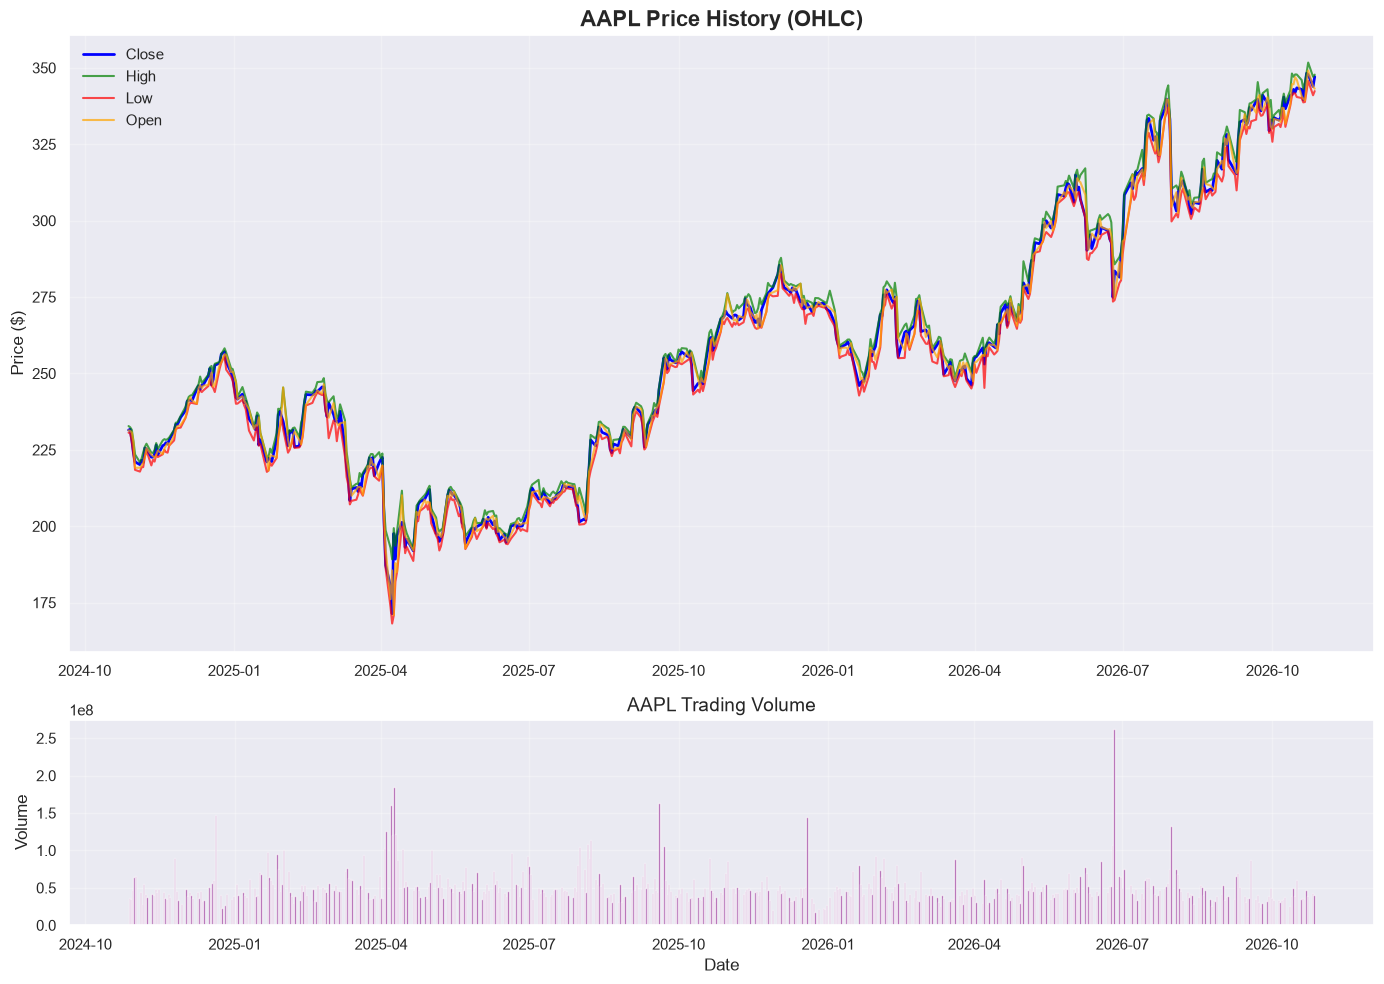

In [14]:
print("Column structure:")
print(stock_data['AAPL'].columns)
print("\nColumn levels:")
print(stock_data['AAPL'].columns.nlevels)

# Create a line plot showing all price components for AAPL
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [3, 1]})

# Plot OHLC prices using correct column indexing
aapl_data = stock_data['AAPL']
ax1.plot(aapl_data.index, aapl_data[('Close', 'AAPL')], label='Close', linewidth=2, color='blue')
ax1.plot(aapl_data.index, aapl_data[('High', 'AAPL')], label='High', alpha=0.7, color='green')
ax1.plot(aapl_data.index, aapl_data[('Low', 'AAPL')], label='Low', alpha=0.7, color='red')
ax1.plot(aapl_data.index, aapl_data[('Open', 'AAPL')], label='Open', alpha=0.7, color='orange')

ax1.set_title('AAPL Price History (OHLC)', fontsize=16, fontweight='bold')
ax1.set_ylabel('Price ($)', fontsize=12)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot volume
ax2.bar(aapl_data.index, aapl_data[('Volume', 'AAPL')], alpha=0.7, color='purple')
ax2.set_title('AAPL Trading Volume', fontsize=14)
ax2.set_ylabel('Volume', fontsize=12)
ax2.set_xlabel('Date', fontsize=12)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

